# Equivariant PDE Discovery: Swift-Hohenberg Equation

We study the **Swift-Hohenberg equation** on $\mathbb{R}^2$:
$$f_t = (r-1)f - 2\Delta f - \Delta^2 f - f^3,\qquad r=0.3.$$

In [1]:
# standard imports
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 4)

# add parent directory with custom library to path
import sys
sys.path.insert(0, '..')

# simulation tools (ground truth data)
from simulations import swift_hohenberg, make_regression_data

# library of PDE terms (respects the active derivative backend)
import derivatives
from library import build_equivariant_library, build_standard_library

# regression tools
from regression import TrainSTRidge

# utilities
from utils import print_pde, rotation_90


## 1. Simulate Swift-Hohenberg via spectral IMEX

The IMEX scheme on the periodic domain $[0, L]^2$:
$$\hat f^{n+1}
=
\frac{
\hat f^n
-
\Delta t\,\widehat{(f^n)^3}
}{
1-\Delta t\left((r-1)+2|k|^2-|k|^4\right)
}
$$

In [47]:
r          = 0.3        # real bifurcation parameter
N          = 128         # grid points per direction
L          = 20*np.pi    # domain side length
T_end      = 60        # end time (endopoint included)
dt         = 0.01        # time step size for integration (not snapshot frequency)
save_every = 200         # save snapshots every 200 steps

snapshots, times = swift_hohenberg(
    N=N, L=L, T_end=T_end, r=r,
    dt=dt, save_every=save_every, seed=42,
)
print(f'Saved {len(snapshots)} snapshots over t ∈ [0, {T_end}]')
print(f'f(t,x) ∈ [{snapshots.min():.3f}, {snapshots.max():.3f}]')

Saved 31 snapshots over t ∈ [0, 60]
f(t,x) ∈ [-0.835, 0.895]


/tmp/ipykernel_152270/1936522955.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


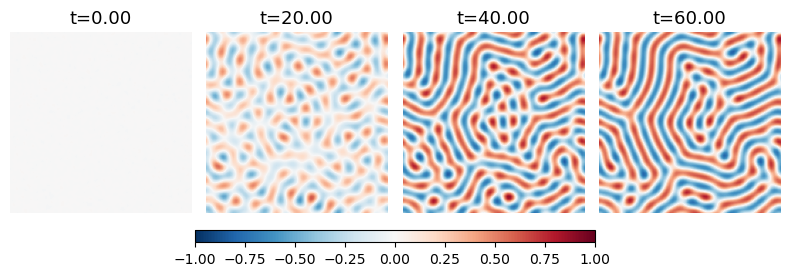

In [48]:
fig,axes=plt.subplots(1,4,figsize=(8,3))

pidx=[0,10,20,-1]
for ax,idx in zip(axes,pidx):
    im=ax.imshow(snapshots[idx],cmap='RdBu_r', vmin=-1,vmax=1,
                 origin='lower',extent=[0,L,0,L])
    ax.set_title(f't={times[idx]:.2f}',fontsize=13); ax.axis('off')

# heatbar below subplots
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.04])
fig.colorbar(im, cax=cbar_ax, orientation='horizontal')

plt.tight_layout()
plt.savefig('../results/figures/swift_hohenberg_snapshots.pdf',bbox_inches='tight')

## 2. Extract data for regression

We estimate $f_t$ by central finite difference between consecutive saved snapshots and randomly subsample spatial points.  Both steps are handled by `simulations.make_regression_data()`.

In [49]:
n_per_snap = 200

f_snaps, ft_snaps, idx_sets, dt_snap = make_regression_data(
    snapshots, times, n_per_snap=n_per_snap, seed=0,
)
Ft_all = np.concatenate([ft_snaps[s].ravel()[idx_sets[s]] for s in range(len(f_snaps))])
print(f'{len(f_snaps)} interior snapshots, dt_snap = {dt_snap:.3f}')
print(f'Total regression points: {len(Ft_all)}')

29 interior snapshots, dt_snap = 2.000
Total regression points: 5800


## 3. Libraries of differential terms

We compute the operator values over the full grid for each snapshot, then subsample.

In [50]:
Theta_eq_rows_spec, Theta_std_rows_spec = [], []
Theta_eq_rows_poly, Theta_std_rows_poly = [], []

for s in range(len(f_snaps)):
    fs  = f_snaps[s]
    idx = idx_sets[s]
    with derivatives.use_backend('spectral'):
        Th_eq,  desc_eq  = build_equivariant_library(fs, L, L)
        Th_std, desc_std = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_spec.append(Th_eq[idx])
    Theta_std_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq,  _ = build_equivariant_library(fs, L, L)
        Th_std, _ = build_standard_library(fs, L, L, max_order=4, max_poly=3)
    Theta_eq_rows_poly.append(Th_eq[idx])
    Theta_std_rows_poly.append(Th_std[idx])

Theta_eq_spec  = np.vstack(Theta_eq_rows_spec).astype(float)
Theta_std_spec = np.vstack(Theta_std_rows_spec).astype(float)
Theta_eq_poly  = np.vstack(Theta_eq_rows_poly).astype(float)
Theta_std_poly = np.vstack(Theta_std_rows_poly).astype(float)

print(f'Library shape : {Theta_eq_spec.shape}')
print(f'Condition numbers (eq / std):')
print(f'  Spectral:   {np.linalg.cond(Theta_eq_spec):.2e} / {np.linalg.cond(Theta_std_spec):.2e}')
print(f'  Polynomial: {np.linalg.cond(Theta_eq_poly):.2e} / {np.linalg.cond(Theta_std_poly):.2e}')


Library shape : (5800, 20)
Condition numbers (eq / std):
  Spectral:   2.13e+03 / 8.35e+02
  Polynomial: 2.18e+03 / 1.02e+03


## 4. Sparse regression (STRidge)

True PDE: $f_t = (r-1)f - 2\Delta f - \Delta^2 f - f^3$ with $r=0.3$.

Expected non-zero coefficients in equivariant library:

| Term | $f$ | $\Delta f$ | $\Delta^2 f$ | $f^3$ |
|---|---|---|---|---|
| Coefficient | -0.7 | -2 | -1 | -1 |


In [51]:
lam   = 1e-5
d_tol = 0.1

print('=== Ground truth PDE ===')
print(f'f_t = {r-1}*f - 2*Δf - Δ²f - f³\n')

print('── Spectral derivatives ──')
w_eq_spec  = TrainSTRidge(Theta_eq_spec,  Ft_all, lam, d_tol)
w_std_spec = TrainSTRidge(Theta_std_spec, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_spec, desc_eq)
print('Standard:');   print_pde(w_std_spec, desc_std)

print('\n── Polynomial derivatives ──')
w_eq_poly  = TrainSTRidge(Theta_eq_poly,  Ft_all, lam, d_tol)
w_std_poly = TrainSTRidge(Theta_std_poly, Ft_all, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_poly, desc_eq)
print('Standard:');   print_pde(w_std_poly, desc_std)

=== Ground truth PDE ===
f_t = -0.7*f - 2*Δf - Δ²f - f³

── Spectral derivatives ──
Equivariant:
f_t = (-0.68590)f + (-0.98048)f³ + (-1.96090)Δf + (-0.98052)Δ²f
Standard:
f_t = (-0.68596)1 + (-1.96092)f_yy + (-1.96105)f_xx + (-0.98041)f_yyyy + (-1.96150)f_xxyy + (-0.98054)f_xxxx + (-0.98048)f^2

── Polynomial derivatives ──
Equivariant:
f_t = (-0.45430)f + (-0.53113)f³ + (-1.25095)Δf + (-0.62846)Δ²f
Standard:
f_t = 0


In [52]:
# Summary comparison — define true_eq for reuse in later cells
true_eq = np.zeros(len(desc_eq))
# Set Swift–Hohenberg ground-truth coefficients by matching descriptions
for i, d in enumerate(desc_eq):
    if d == 'f':
        true_eq[i] = (r - 1)
    elif d == 'f³':
        true_eq[i] = -1.0
    elif d == 'Δf':
        true_eq[i] = -2.0
    elif d == 'Δ²f':
        true_eq[i] = -1.0
act = np.abs(true_eq) > 1e-10

print('--- Recovery summary (clean data) ---')
print(f"True: f → {r-1:.4f}, Δf → -2.0, Δ²f → -1.0, f³ → -1.0\n")

for tag, w in [('Spectral  eq', w_eq_spec), ('Polynomial eq', w_eq_poly)]:
    nz  = np.count_nonzero(np.abs(w) > 1e-10)
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: {nz} active, fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

for tag, w in [('Spectral  std', w_std_spec), ('Polynomial std', w_std_poly)]:
    nz = np.count_nonzero(np.abs(w) > 1e-10)
    print(f'  {tag}: {nz} active terms out of {len(w)}')

--- Recovery summary (clean data) ---
True: f → -0.7000, Δf → -2.0, Δ²f → -1.0, f³ → -1.0

  Spectral  eq: 4 active, fp=0, fn=0, max_coeff_err=3.910e-02
  Polynomial eq: 4 active, fp=0, fn=0, max_coeff_err=7.490e-01
  Spectral  std: 7 active terms out of 60
  Polynomial std: 0 active terms out of 60


## 5. Robustness to noise

We benchmark with added **observation noise**.

In [53]:
noise_level = 0.02   # 2% of clean snapshot std

snapshots_noisy, _ = swift_hohenberg(
    N=N, L=L, T_end=T_end, r=r,
    dt=dt, save_every=save_every, seed=42,
    obs_noise=noise_level,
)

f_snaps_n, ft_snaps_n, idx_sets_n, _ = make_regression_data(
    snapshots_noisy, times, n_per_snap=n_per_snap, seed=0,
)
Ft_n = np.concatenate([ft_snaps_n[s].ravel()[idx_sets_n[s]] for s in range(len(f_snaps_n))])

Theta_eq_n_rows_spec, Theta_std_n_rows_spec = [], []
Theta_eq_n_rows_poly, Theta_std_n_rows_poly = [], []

for s in range(len(f_snaps_n)):
    idx = idx_sets_n[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_spec.append(Th_eq[idx])
    Theta_std_n_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_n[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_n[s], L, L, max_order=4, max_poly=3)
    Theta_eq_n_rows_poly.append(Th_eq[idx])
    Theta_std_n_rows_poly.append(Th_std[idx])

Theta_eq_n_spec  = np.vstack(Theta_eq_n_rows_spec).astype(float)
Theta_std_n_spec = np.vstack(Theta_std_n_rows_spec).astype(float)
Theta_eq_n_poly  = np.vstack(Theta_eq_n_rows_poly).astype(float)
Theta_std_n_poly = np.vstack(Theta_std_n_rows_poly).astype(float)
print(f'Noisy: {len(Ft_n)} regression points, noise={noise_level*100:.0f}%')


Noisy: 5800 regression points, noise=2%


In [54]:
print('=== Ground truth PDE ===')
print(f'f_t = {r-1}*f - 2*Δf - Δ²f - f³\n')

print(f'── Spectral (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_spec  = TrainSTRidge(Theta_eq_n_spec,  Ft_n, lam, d_tol)
w_std_n_spec = TrainSTRidge(Theta_std_n_spec, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_spec, desc_eq)
print('Standard:');   print_pde(w_std_n_spec, desc_std)

print(f'\n── Polynomial (obs_noise = {noise_level*100:.0f}%) ──')
w_eq_n_poly  = TrainSTRidge(Theta_eq_n_poly,  Ft_n, lam, d_tol)
w_std_n_poly = TrainSTRidge(Theta_std_n_poly, Ft_n, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_n_poly, desc_eq)
print('Standard:');   print_pde(w_std_n_poly, desc_std)

print('\n--- Noisy recovery summary ---')
for tag, w in [('Spectral  eq', w_eq_n_spec), ('Polynomial eq', w_eq_n_poly)]:
    fp  = int(np.sum((np.abs(w) > 1e-10) & ~act))
    fn  = int(np.sum((np.abs(w) < 1e-10) &  act))
    err = float(np.max(np.abs(w[act] - true_eq[act])))
    print(f'  {tag}: fp={fp}, fn={fn}, max_coeff_err={err:.3e}')

=== Ground truth PDE ===
f_t = -0.7*f - 2*Δf - Δ²f - f³

── Spectral (obs_noise = 2%) ──
Equivariant:
f_t = 0
Standard:
f_t = 0

── Polynomial (obs_noise = 2%) ──
Equivariant:
f_t = (+0.11850)f + (-0.28361)f³ + (-0.20050)f²·Δf + (-0.33088)f·‖∇f‖² + (-0.23847)f·‖∇²f‖²
Standard:
f_t = 0

--- Noisy recovery summary ---
  Spectral  eq: fp=0, fn=4, max_coeff_err=2.000e+00
  Polynomial eq: fp=3, fn=2, max_coeff_err=2.000e+00


## 6. Equivariance test

We rotate the data by 90° and repeat the regression.

In [10]:
# Rotate all snapshots 90° and re-run the same pipeline
snaps_r = rotation_90(snapshots.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_r, ft_snaps_r, idx_sets_r, _ = make_regression_data(
    snaps_r, times, n_per_snap=n_per_snap, seed=0,
)
Ft_r = np.concatenate([ft_snaps_r[s].ravel()[idx_sets_r[s]] for s in range(len(f_snaps_r))])

Theta_eq_r_rows_spec, Theta_std_r_rows_spec = [], []
Theta_eq_r_rows_poly, Theta_std_r_rows_poly = [], []

for s in range(len(f_snaps_r)):
    idx = idx_sets_r[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_spec.append(Th_eq[idx])
    Theta_std_r_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_r[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_r[s], L, L, max_order=4, max_poly=3)
    Theta_eq_r_rows_poly.append(Th_eq[idx])
    Theta_std_r_rows_poly.append(Th_std[idx])

Theta_eq_r_spec  = np.vstack(Theta_eq_r_rows_spec).astype(float)
Theta_std_r_spec = np.vstack(Theta_std_r_rows_spec).astype(float)
Theta_eq_r_poly  = np.vstack(Theta_eq_r_rows_poly).astype(float)
Theta_std_r_poly = np.vstack(Theta_std_r_rows_poly).astype(float)

print('── Spectral (rotated clean) ──')
w_eq_r_spec  = TrainSTRidge(Theta_eq_r_spec,  Ft_r, lam, d_tol)
w_std_r_spec = TrainSTRidge(Theta_std_r_spec, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_spec, desc_eq)
print('Standard:');   print_pde(w_std_r_spec, desc_std)

print('\n── Polynomial (rotated clean) ──')
w_eq_r_poly  = TrainSTRidge(Theta_eq_r_poly,  Ft_r, lam, d_tol)
w_std_r_poly = TrainSTRidge(Theta_std_r_poly, Ft_r, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_r_poly, desc_eq)
print('Standard:');   print_pde(w_std_r_poly, desc_std)


── Spectral (rotated clean) ──
Equivariant:
f_t = (-0.68733)f + (-0.98230)f³ + (-1.96446)Δf + (-0.98228)Δ²f
Standard:
f_t = (-0.68733)1 + (-1.96436)f_yy + (-1.96453)f_xx + (-0.98217)f_yyyy + (-1.96466)f_xxyy + (-0.98232)f_xxxx + (-0.98230)f^2

── Polynomial (rotated clean) ──
Equivariant:
f_t = (-0.33280)f + (-0.37317)f³ + (-0.90441)Δf + (-0.45312)Δ²f
Standard:
f_t = 0


In [11]:
print('Coefficient change under 90° rotation (clean data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_spec,  w_eq_r_spec),
    ('Polynomial eq', w_eq_poly,  w_eq_r_poly),
    ('Spectral  std', w_std_spec, w_std_r_spec),
    ('Polynomial std',w_std_poly, w_std_r_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')

Coefficient change under 90° rotation (clean data):
  Spectral  eq: max|Δc| = 7.94e-04
  Polynomial eq: max|Δc| = 2.27e-03
  Spectral  std: max|Δc| = 9.24e-04
  Polynomial std: max|Δc| = 0.00e+00


In [12]:
snaps_noisy_r = rotation_90(snapshots_noisy.transpose(1, 2, 0)).transpose(2, 0, 1)

f_snaps_rn, ft_snaps_rn, idx_sets_rn, _ = make_regression_data(
    snaps_noisy_r, times, n_per_snap=n_per_snap, seed=0,
)
Ft_rn = np.concatenate([ft_snaps_rn[s].ravel()[idx_sets_rn[s]] for s in range(len(f_snaps_rn))])

Theta_eq_rn_rows_spec, Theta_std_rn_rows_spec = [], []
Theta_eq_rn_rows_poly, Theta_std_rn_rows_poly = [], []

for s in range(len(f_snaps_rn)):
    idx = idx_sets_rn[s]
    with derivatives.use_backend('spectral'):
        Th_eq, _  = build_equivariant_library(f_snaps_rn[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_rn[s], L, L, max_order=4, max_poly=3)
    Theta_eq_rn_rows_spec.append(Th_eq[idx])
    Theta_std_rn_rows_spec.append(Th_std[idx])
    with derivatives.use_backend('polynomial'):
        Th_eq, _  = build_equivariant_library(f_snaps_rn[s], L, L)
        Th_std, _ = build_standard_library(f_snaps_rn[s], L, L, max_order=4, max_poly=3)
    Theta_eq_rn_rows_poly.append(Th_eq[idx])
    Theta_std_rn_rows_poly.append(Th_std[idx])

Theta_eq_rn_spec  = np.vstack(Theta_eq_rn_rows_spec).astype(float)
Theta_std_rn_spec = np.vstack(Theta_std_rn_rows_spec).astype(float)
Theta_eq_rn_poly  = np.vstack(Theta_eq_rn_rows_poly).astype(float)
Theta_std_rn_poly = np.vstack(Theta_std_rn_rows_poly).astype(float)

print('── Spectral (noisy + rotated) ──')
w_eq_rn_spec  = TrainSTRidge(Theta_eq_rn_spec,  Ft_rn, lam, d_tol)
w_std_rn_spec = TrainSTRidge(Theta_std_rn_spec, Ft_rn, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_rn_spec, desc_eq)
print('Standard:');   print_pde(w_std_rn_spec, desc_std)

print('\n── Polynomial (noisy + rotated) ──')
w_eq_rn_poly  = TrainSTRidge(Theta_eq_rn_poly,  Ft_rn, lam, d_tol)
w_std_rn_poly = TrainSTRidge(Theta_std_rn_poly, Ft_rn, lam, d_tol)
print('Equivariant:'); print_pde(w_eq_rn_poly, desc_eq)
print('Standard:');   print_pde(w_std_rn_poly, desc_std)


── Spectral (noisy + rotated) ──
Equivariant:
f_t = 0
Standard:
f_t = 0

── Polynomial (noisy + rotated) ──
Equivariant:
f_t = 0
Standard:
f_t = 0


In [13]:
print('Coefficient change under 90° rotation (noisy data):')
for tag, w, wr in [
    ('Spectral  eq',  w_eq_n_spec,  w_eq_rn_spec),
    ('Polynomial eq', w_eq_n_poly,  w_eq_rn_poly),
    ('Spectral  std', w_std_n_spec, w_std_rn_spec),
    ('Polynomial std',w_std_n_poly, w_std_rn_poly),
]:
    print(f'  {tag}: max|Δc| = {np.max(np.abs(w - wr)):.2e}')

Coefficient change under 90° rotation (noisy data):
  Spectral  eq: max|Δc| = 1.66e-01
  Polynomial eq: max|Δc| = 5.23e-01
  Spectral  std: max|Δc| = 0.00e+00
  Polynomial std: max|Δc| = 0.00e+00
